# Reproducing "Tessa: Encoding Classical Data Across an Entire Quantum Processor"

D. Bultrini (Moth Quantum); arXiv identifier to be added on publication.

Tessa writes classical real numbers onto every qubit of a quantum processor. The
device's coupling graph is 2-coloured into data qubits, which hold the values, and
address qubits, which are shared between neighbouring data qubits as control
registers. Each data qubit stores `2**degree` values with a uniformly controlled
rotation, the circuit needs no SWAP gates, and one measurement setting (two for the
pair encoding) reads every value. The paper runs it on IBM's `ibm_phoenix` (square
lattice, 120 qubits) and `ibm_fez` (heavy hex, 156 qubits).

This notebook regenerates every experimental and simulation figure and table of the
paper from the data stored in this repository, in the order of the paper, and
compares each printed number (and each printed label and qualitative claim) with the
value computed from the data. Where the published figure is a PNG it is shown below
the regenerated one; the published PDF figures (Figs. 6, 10, 14) are not rasterised
here and can be opened from `figures/paper/`. It needs no IBM
account. From a fresh kernel it runs in about 30 s (measured on a 4-core VM).

Repository layout used here:

| folder | content |
|---|---|
| `data/` | inputs before encoding: images, MIDI files, genetic sequences |
| `results/hardware/` | what came back from the quantum computers: counts, shots, job records, submitted circuits, and the derived reconstructions and statistics used in the paper |
| `results/simulation/` | stored simulation outputs (noiseless and noise-model runs) |
| `figures/paper/` | the figures as published, for comparison |
| `figures/` | figures written by this notebook (not committed) |
| `src/tessa/` | the library |
| `src/tessa_paper/` | one module per paper item; the functions called below |

Install (Python >= 3.11) from a clone of the repository:

```
pip install -e ".[notebooks]"
```

Differences between the paper and the stored data are listed in each section and
documented in full in `REPRODUCIBILITY.md`. One level below the stored derived data
(re-decoding raw counts and shots, re-running simulations) is
`notebooks/rerun_from_raw.ipynb`.

## Contents

Status: *exact* = every number printed in the paper is reproduced from the stored
data (and the figure is pixel- or byte-identical where stated); *reproduced* = all
data and numbers reproduced, the drawing differs in rendering or layout;
*simulation* = reproduced, but the stored data are a simulation although the paper
labels them as hardware; *re-creation* = the paper's data were not saved, a
simulation of the same procedure is shown instead; *not reproducible* = neither data
nor code survive. A "known difference" is a number for which the paper and the
stored data disagree; it is listed and explained, not corrected.

| paper item | notebook section | status |
|---|---|---|
| Fig. 1 (teaser) | 1 | reproduced from data (the paper crops Figs. 4 and 6) |
| Fig. 2, Fig. 3 (lattice and circuit schematics) | - | schematics, no data |
| Fig. 4 (QCAT on hardware) | 1 | exact (compact panels pixel-identical) |
| Fig. 5 (coupling graphs) | 2 | (a) new drawing of the same graph, (b) reproduced |
| Fig. 6 (pixel art) | 3 | reproduced; one label differs (16384 vs 8192 shots) |
| Table 1 (hardware results) | 4 | exact (50 numbers) |
| Abstract, "up to 1584 real values" | 4 | known difference (1568 encoded; 1584 is the capacity) |
| Table 2 (prior work, Tessa rows) | 5 | reproduced; 2Q depth differs (23/43 vs 19/39) |
| Fig. 7, Fig. 8, Table 3 (App. C, entanglement) | 6 | exact |
| Table 4 (App. D, shot cost) | 7 | not reproducible; payload-independent column reproduced |
| Fig. 9 (App. D, coherences) | 7 | exact numbers; shows experiment B (pixel pairs) |
| Table 5 (App. E, modes) | 8 | exact |
| Fig. 10 (App. E, clamp region) | 8 | schematic, no data |
| Fig. 11 (App. E, clamp sweep) | 8 | exact |
| Table 6 (App. F, dynamic-range recovery) | 9 | image columns exact; pitch columns simulation |
| Fig. 12 (App. G, wavetable) | 10 | re-creation (hardware data not saved) |
| Table 7 (App. G, MIDI) | 11 | simulation (all numbers reproduced) |
| Fig. 13 (App. G, constellation) | 12 | exact (byte-identical TikZ) |
| Fig. 14, Table 8 (App. G, genetic sequences) | 12 | exact (byte-identical LaTeX table) |

Every comparison has a kind: a printed *number* (a table cell such as `92.3 (ms)`
counts as one), a printed *label* or LaTeX macro (method names, job ids, dates, a
file that must be identical), a qualitative *claim* of the text ("about 3", "agree"),
or a value *not printed* in the paper (shown for completeness). Section 13 counts
them separately and records the software versions.

In [ ]:
import io
import platform
import time
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from tessa_paper import (
    audio_midi,
    checks,
    circuits,
    coherence,
    entanglement,
    genetic,
    lattices,
    pair_encoding,
    pixel_art,
    qcat,
)
from tessa_paper.paths import FIGURES

START = time.perf_counter()
PAPER = FIGURES / "paper"
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)


def show(fig, dpi=90):
    """Display a figure inline at a moderate resolution and close it."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    display(Image(buf.getvalue()))


def reference(name, width=None):
    """Display a published figure from figures/paper/."""
    display(Markdown(f"Published figure, `figures/paper/{name}`:"))
    display(Image(filename=str(PAPER / name), width=width))


def pixel_comparison(new, published):
    """Compare a regenerated PNG with the published one, pixel by pixel.

    Images of different size are not compared; both sizes are reported instead.
    """
    a = np.asarray(PILImage.open(FIGURES / new).convert("RGB"))
    b = np.asarray(PILImage.open(PAPER / published).convert("RGB"))
    if a.shape == b.shape:
        differing = f"{np.any(a != b, axis=-1).mean():.4f}"
    else:
        differing = "not compared: sizes differ"
    return pd.Series(
        {
            "regenerated": f"figures/{new} {a.shape[1]}x{a.shape[0]}",
            "published": f"figures/paper/{published} {b.shape[1]}x{b.shape[0]}",
            "fraction of differing pixels": differing,
        }
    )


CHECKS = {}


def check(name, *prefixes, table=None):
    """Rows of ``<module>.check_against_paper()`` whose item starts with a prefix.

    Columns: item, paper, reproduced, match, kind (number, label, claim or not
    printed) and status: "match", "known difference" (listed in the module's
    KNOWN_DISCREPANCIES and in REPRODUCIBILITY.md) or "UNEXPECTED" (none occur).
    ``table`` reuses a check table computed before (genetic).
    """
    if name not in CHECKS:
        if table is None:
            CHECKS[name] = checks.check_table(name)
        else:
            CHECKS[name] = table.assign(
                module=name,
                status=np.where(table["match"], "match", "known difference"),
            )
            known = set(checks.MODULES[name].KNOWN_DISCREPANCIES)
            bad = ~CHECKS[name]["match"] & ~CHECKS[name]["item"].isin(known)
            CHECKS[name].loc[bad, "status"] = "UNEXPECTED"
    df = CHECKS[name].drop(columns="module")
    if prefixes:
        df = df[df["item"].str.startswith(prefixes)]
    return df.reset_index(drop=True)


def summary(name, *prefixes):
    """One line per kind: how many comparisons match."""
    df = check(name, *prefixes)
    for kind, part in df.groupby("kind", sort=False):
        counts = part["status"].value_counts()
        text = ", ".join(f"{n} {s}" for s, n in counts.items())
        print(f"{kind}: {len(part)} compared with the paper: {text}.")

## 1. Fig. 4 (QCAT on the whole chip) and Fig. 1 (teaser)

The QCAT image was encoded on every qubit of `ibm_phoenix` (28x28, 784 values) and
of `ibm_fez` (21x21, 441 values), once in the single encoding (one value per slot,
Z readout) and once in the pair encoding (value in theta read in Z, hue in phi read
in X), at 8192 shots per basis (jobs of 2026-09-26). The figures are drawn from the
paper's analysis, `results/hardware/qcat/stats.json` and `reconstructions.npz`
(value-only `mean_std` dynamic-range recovery, no clipping). The City-pop cat row of
the teaser comes from `results/hardware/pixel_art/PixelArt/`.

Fig. 4 (a): single encoding, Z readout.

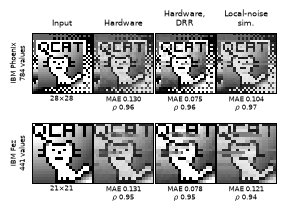

Published figure, `figures/paper/fig_qcat_hardware_z_compact.png`:

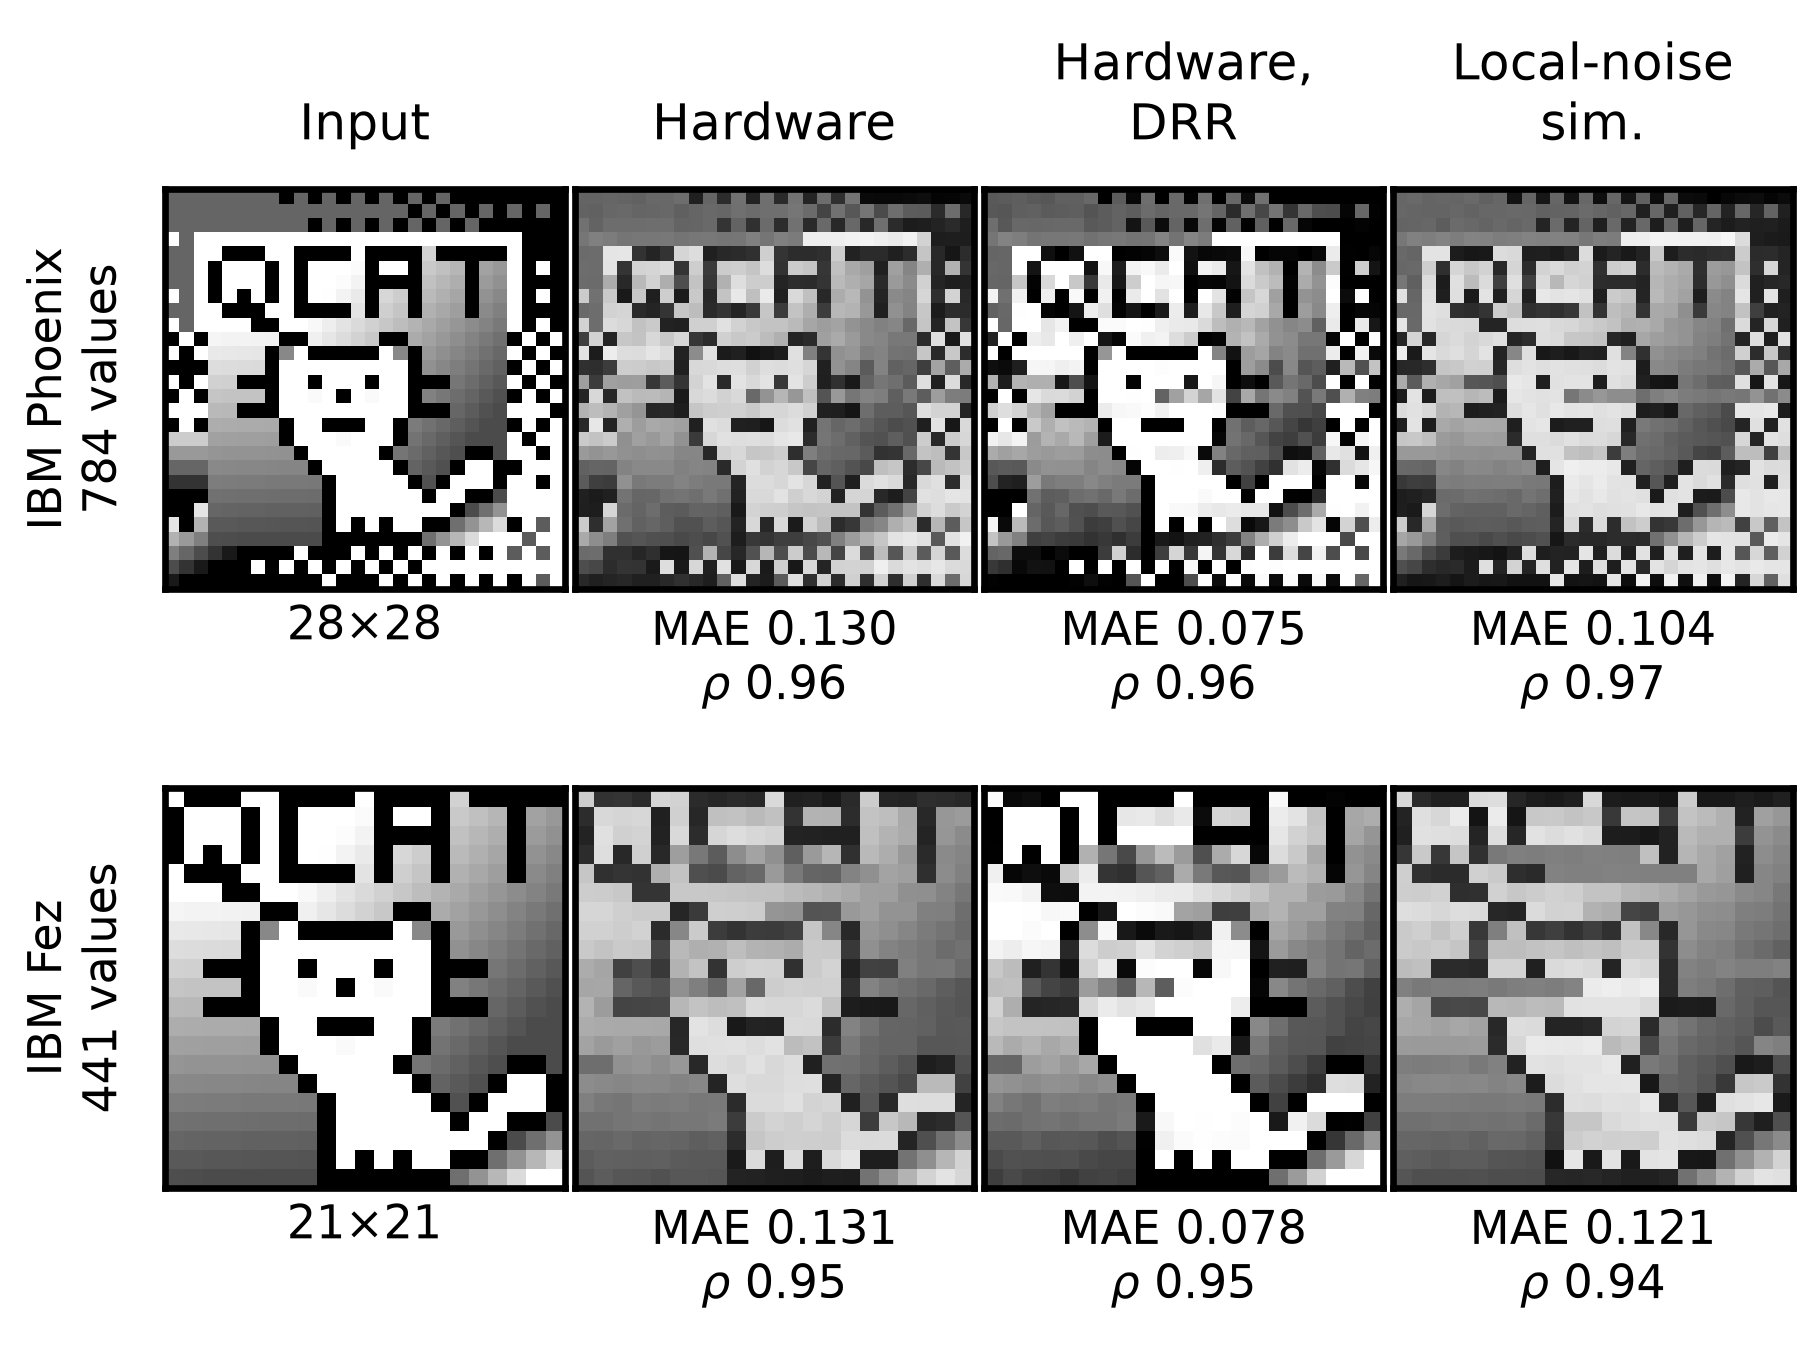

In [2]:
show(
    qcat.qcat_figure(
        "single", compact=True, save=FIGURES / "fig_qcat_hardware_z_compact.png"
    )
)
reference("fig_qcat_hardware_z_compact.png", width=480)

Fig. 4 (b): pair encoding, value (Z) and hue (X).

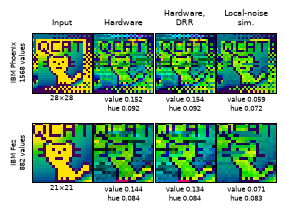

Published figure, `figures/paper/fig_qcat_hardware_zx_compact.png`:

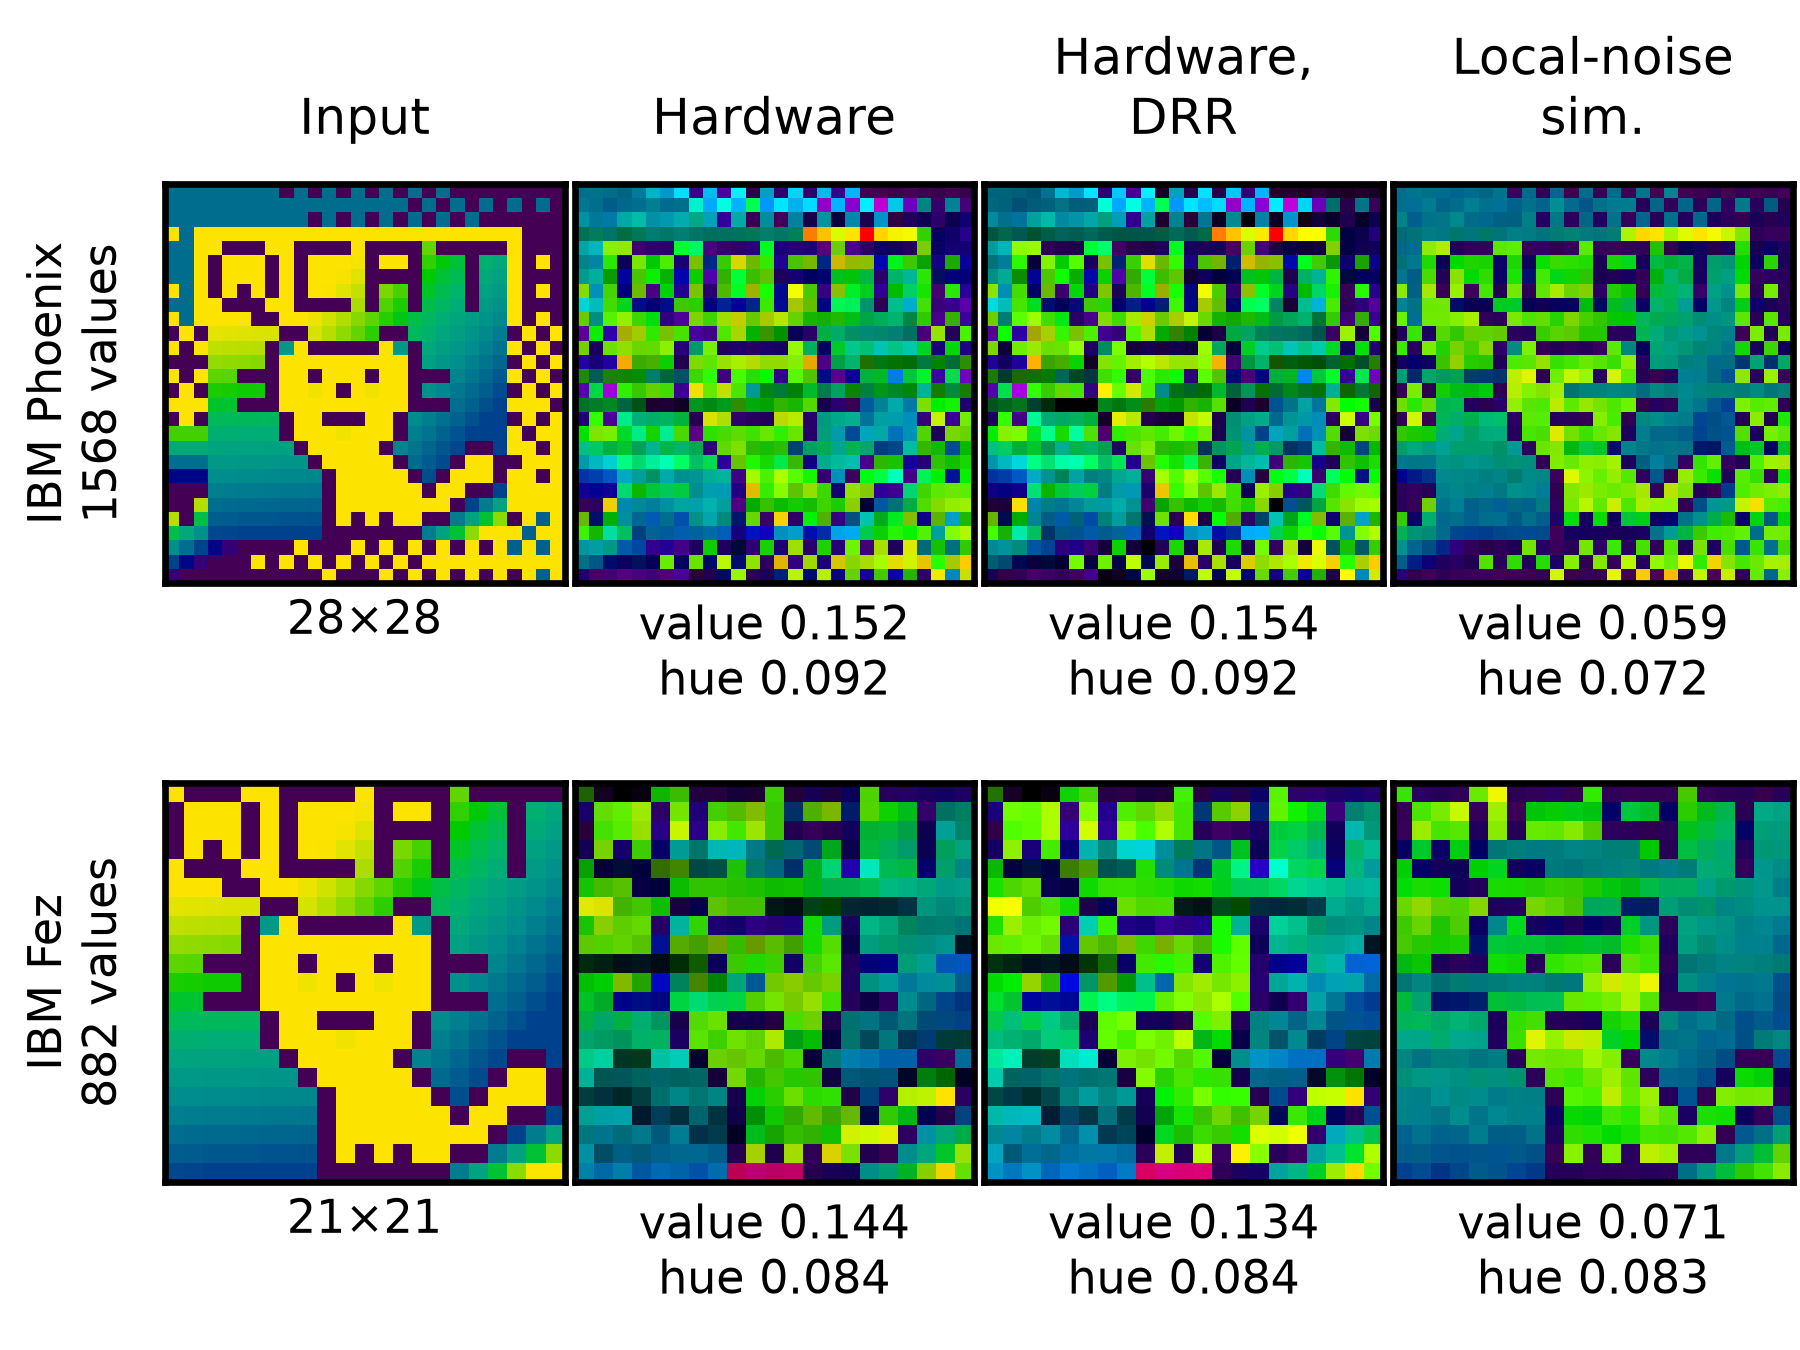

In [3]:
show(
    qcat.qcat_figure(
        "pair", compact=True, save=FIGURES / "fig_qcat_hardware_zx_compact.png"
    )
)
reference("fig_qcat_hardware_zx_compact.png", width=480)

The regenerated compact panels (written at 600 dpi) compared with the published
PNGs:

In [4]:
pd.DataFrame(
    [
        pixel_comparison(
            "fig_qcat_hardware_z_compact.png", "fig_qcat_hardware_z_compact.png"
        ),
        pixel_comparison(
            "fig_qcat_hardware_zx_compact.png", "fig_qcat_hardware_zx_compact.png"
        ),
    ]
)

,regenerated,published,fraction of differing pixels
0,figures/fig_qcat_hardware_z_compact.png 1800x1350,figures/paper/fig_qcat_hardware_z_compact.png 1800x1350,0.0000
1,figures/fig_qcat_hardware_zx_compact.png 1800x1350,figures/paper/fig_qcat_hardware_zx_compact.png 1800x1350,0.0000


The full versions add the local-noise simulation after DRR. The top-left panels of
the single-encoding version are what the paper crops for the teaser.

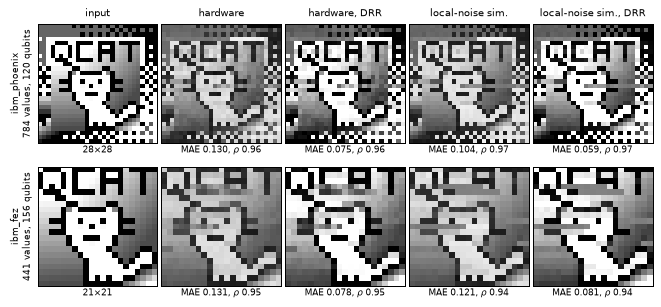

In [5]:
show(qcat.qcat_figure("single", compact=False, save=FIGURES / "fig_qcat_hardware_z.png"))

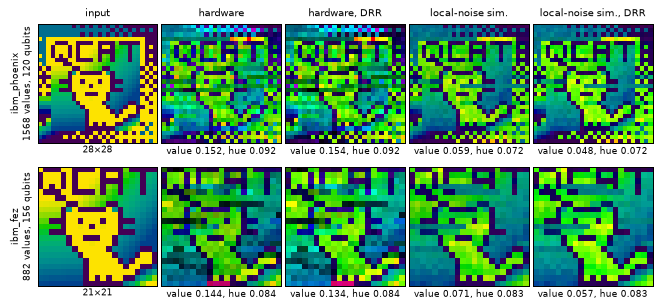

In [6]:
show(qcat.qcat_figure("pair", compact=False, save=FIGURES / "fig_qcat_hardware_zx.png"))

The published full single-encoding figure (`fig_qcat_hardware_z.png`, of which the
paper crops the top-left panels for Fig. 1) next to the regenerated one. It was made
with matplotlib 3.10.9; with other versions the text renders differently
(REPRODUCIBILITY.md, section e).

Published figure, `figures/paper/fig_qcat_hardware_z.png`:

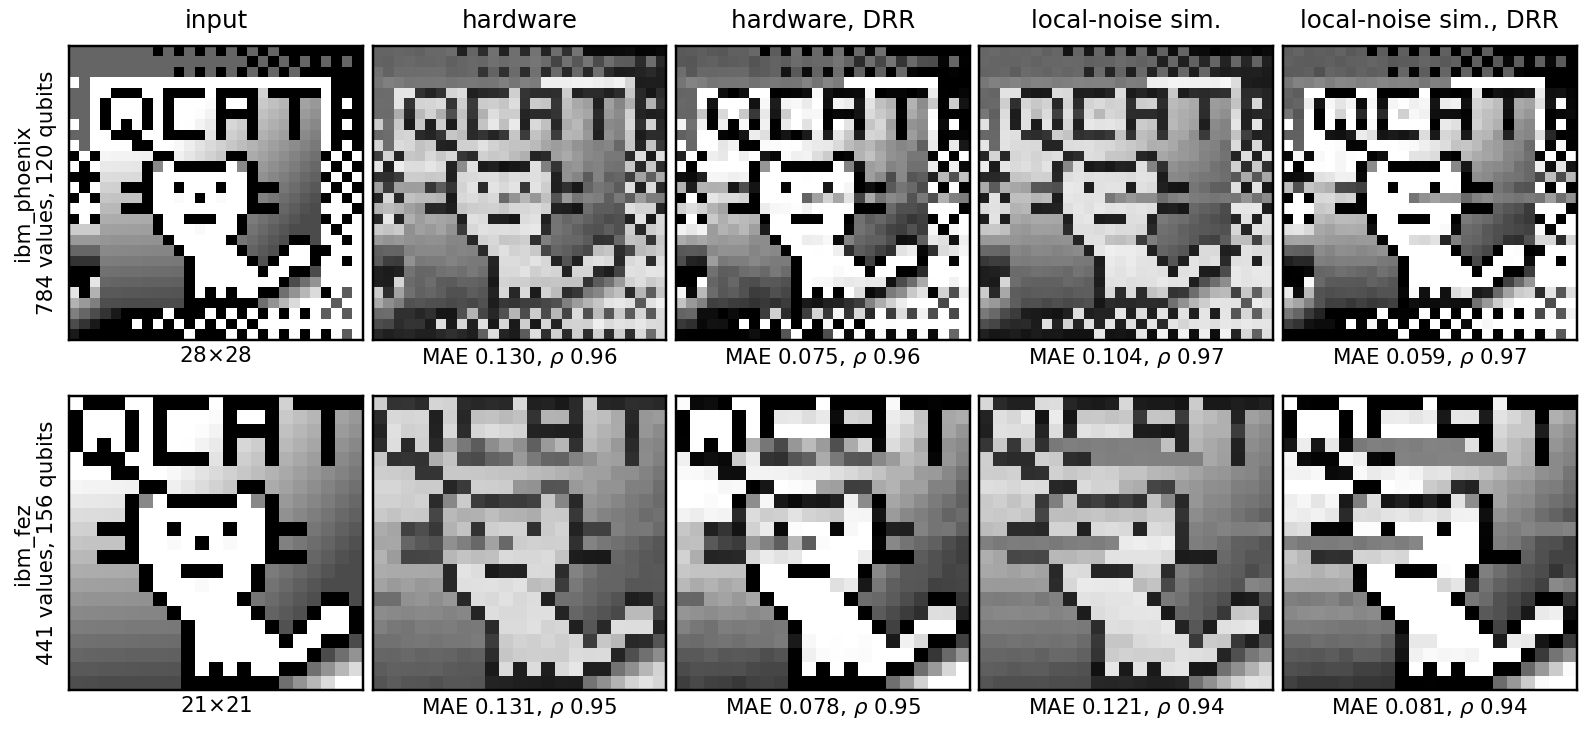

regenerated                           figures/fig_qcat_hardware_z.png 1584x737
published                       figures/paper/fig_qcat_hardware_z.png 1584x737
fraction of differing pixels                                            0.3967
dtype: str

In [7]:
reference("fig_qcat_hardware_z.png", width=700)
pixel_comparison("fig_qcat_hardware_z.png", "fig_qcat_hardware_z.png")

Fig. 1 (teaser), built from the stored reconstructions rather than cropped:
QCAT (784 values, Phoenix, Z) and City-pop cat (784 pixels, value and hue, 1568
values). The paper crops its two rows from `fig_qcat_hardware_z.png` (shown above)
and from `fig_pixelart.pdf` (section 3).

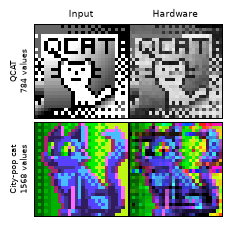

,item,paper,reproduced,match,kind,status
0,fig:teaser City-pop cat values,1568,1568,True,number,match
1,fig:teaser City-pop cat shots,8192,8192,True,number,match


In [8]:
show(qcat.teaser_figure(save=FIGURES / "fig_teaser.png"))
check("pixel_art", "fig:teaser")

## 2. Fig. 5 (coupling graphs and their 2-colouring)

Data qubits blue, address qubits orange. The coupling maps come from the
calibration snapshots shipped with `tessa.hardware` and are checked to equal the
graphs stored with the QCAT runs (`results/hardware/qcat/encodings.json`). The
script of the published heavy-hex drawing (a) is lost; (a) below is a new drawing
of the same graph and colouring with a regular layout.

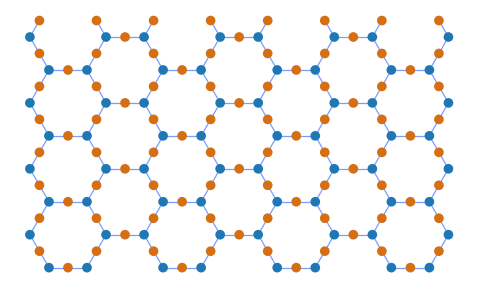

Published figure, `figures/paper/fig_heavyhex.png`:

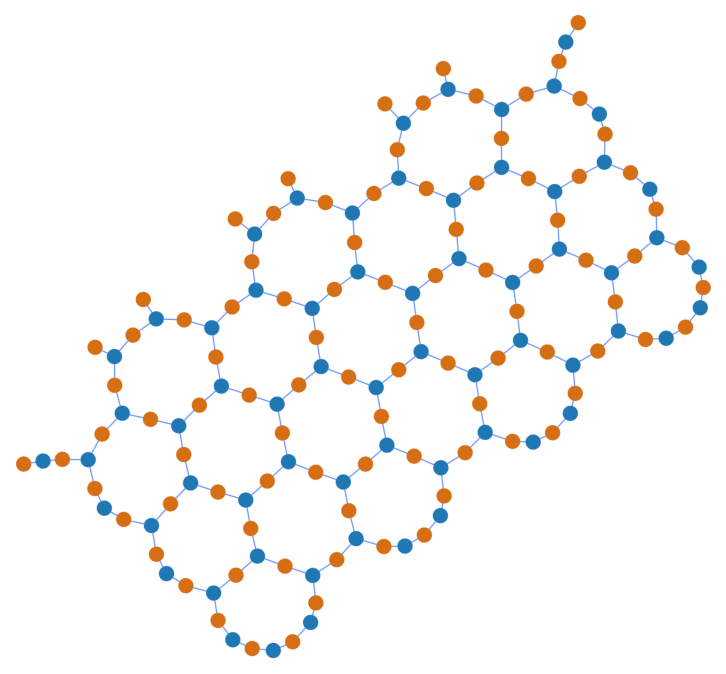

In [9]:
show(lattices.heavy_hex_figure(save=FIGURES / "fig_heavyhex.png"))
reference("fig_heavyhex.png", width=300)

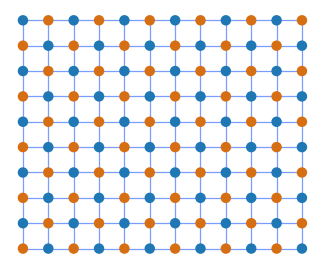

Published figure, `figures/paper/fig_square_lattice.png`:

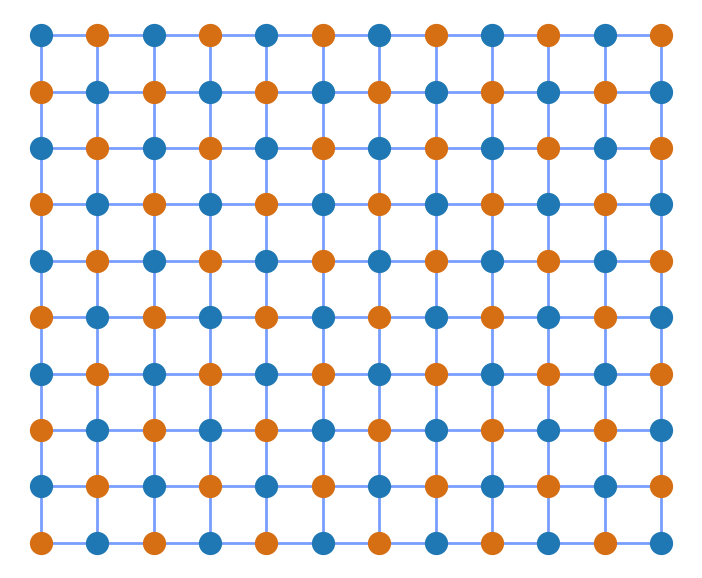

regenerated                           figures/fig_square_lattice.png 702x578
published                       figures/paper/fig_square_lattice.png 702x578
fraction of differing pixels                                          0.0362
dtype: str

In [10]:
show(lattices.square_lattice_figure(save=FIGURES / "fig_square_lattice.png"))
reference("fig_square_lattice.png", width=300)
pixel_comparison("fig_square_lattice.png", "fig_square_lattice.png")

In [11]:
lattices.capacity_table()

,backend,qubits,couplers,data,address,capacity,data qubits by degree,same graph as the QCAT runs
device,,,,,,,,
fez,ibm_fez,156,176,64,92,448,"{2: 16, 3: 48}",True
phoenix,ibm_phoenix,120,218,60,60,792,"{2: 2, 3: 18, 4: 40}",True


In [12]:
check("lattices", "fig:hh")

,item,paper,reproduced,match,kind,status
0,fig:hh Fez capacity,448,448,True,number,match
1,fig:hh Phoenix capacity,792,792,True,number,match


## 3. Fig. 6 (pixel art on Phoenix)

Seven images and three transitions were encoded on `ibm_phoenix` in two hardware
packages, `results/hardware/pixel_art/PixelArt` (job `dbbpav9gv2cc73e8u8ig`) and
`Pixels2` (job `dbcdje7i0auc73duo9ag`). The figure reads the encoded inputs from
`requests/<label>.json` and the decoded images and metrics from
`results/<label>/result.json`. 

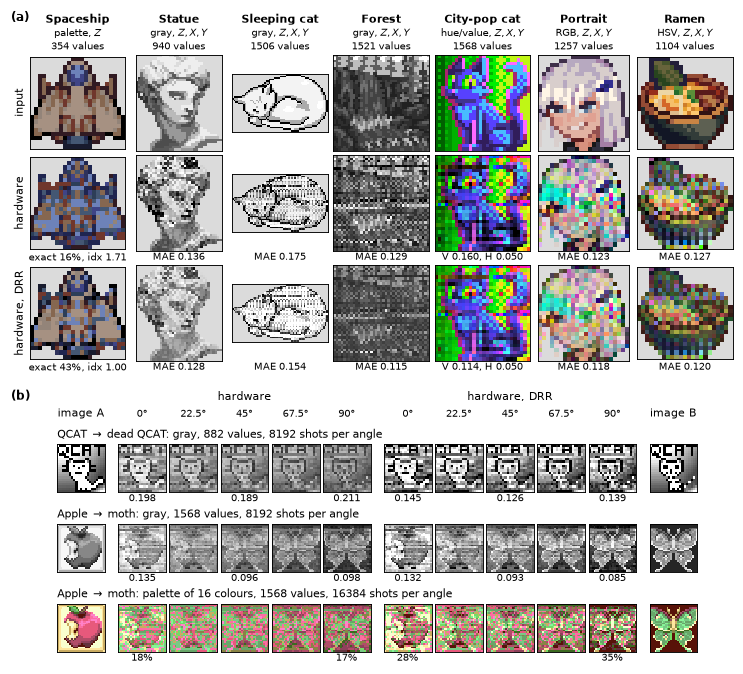

In [13]:
show(pixel_art.pixelart_figure(save=FIGURES / "fig_pixelart.pdf"), dpi=110)

In [ ]:
print("Hand edits of the published PDF (pixel_art.PUBLISHED_FIGURE_EDITS):")
for edit in pixel_art.PUBLISHED_FIGURE_EDITS:
    print("-", edit)

The metrics printed in the figure, per run (errors on [0, 1]; hue as a fraction of
the circle).

In [15]:
pixel_art.metrics_table()

,package,label,name,panel,representation,values,shots,DRR method,metric,raw,DRR
0,PixelArt,spaceship,Spaceship,a,palette,354,8192,mean_std,exact,0.155367,0.426554
1,PixelArt,spaceship,Spaceship,a,palette,354,8192,mean_std,idx,1.709040,0.997175
2,PixelArt,statue,Statue,a,gray,940,8192,percentile,MAE,0.136216,0.128245
3,PixelArt,sleepingCat,Sleeping cat,a,gray,1506,8192,mean_std,MAE,0.175016,0.154372
4,Pixels2,forest,Forest,a,gray,1521,8192,min_avg_max,MAE,0.129202,0.114990
5,PixelArt,citypopcat,City-pop cat,a,huevalue,1568,8192,mean_std,V,0.159911,0.113614
6,PixelArt,citypopcat,City-pop cat,a,huevalue,1568,8192,mean_std,H,0.049693,0.049693
7,PixelArt,anime,Portrait,a,color,1257,8192,percentile,MAE,0.123194,0.117922
8,Pixels2,ramen,Ramen,a,color,1104,8192,min_avg_max,MAE,0.127328,0.119772
9,PixelArt,cat_transition,QCAT -> dead QCAT,b,transition (gray),882,8192,mean_std,A at 0,0.198016,0.144933


In [16]:
check("pixel_art", "fig:pixelart").query("status != 'match'")

,item,paper,reproduced,match,kind,status
53,fig:pixelart Apple -> moth (palette) shots,8192,16384,False,number,known difference


In [17]:
summary("pixel_art")

number: 52 compared with the paper: 51 match, 1 known difference.
label: 10 compared with the paper: 10 match.


## 4. Table 1 (hardware results) and the numbers of Sec. 3

Value MAE (raw and after `mean_std` DRR), Pearson correlation and hue MAE of the
QCAT runs on hardware, in the local-noise simulation and without noise. Shown at
full precision; the paper prints three decimals (two for rho). The metrics are
computed here from images: the hardware images are decoded from the raw counts
(`results/hardware/qcat/counts/`), the simulations are the stored raw decodes
(`results/simulation/qcat/sim.npz`), the inputs are read from `data/images/qcat/`,
and DRR is `tessa.apply_dynamic_range(value, input, "mean_std")`. The stored
analysis (`results/hardware/qcat/stats.json`) serves as a cross-check.

In [18]:
qcat.hardware_table()

values    CZ  value MAE       DRR  value rho   hue MAE
run          source                                                            
Phoenix, Z   hardware       784   728   0.129887  0.074741   0.959219       NaN
             local sim.     784   728   0.104340  0.058607   0.967893       NaN
             noiseless      784   728   0.003955  0.004084   0.999808       NaN
Fez, Z       hardware       441   428   0.131244  0.077570   0.952858       NaN
             local sim.     441   428   0.121022  0.080878   0.943714       NaN
             noiseless      441   428   0.003663  0.003890   0.999861       NaN
Phoenix, Z,X hardware      1568  1456   0.152162  0.154148   0.687755  0.092386
             local sim.    1568  1456   0.059220  0.047866   0.940833  0.071911
             noiseless     1568  1456   0.017505  0.017384   0.996725  0.024668
Fez, Z,X     hardware       882   852   0.143579  0.133528   0.731848  0.084370
             local sim.     882   852   0.070835  0.056693   0.927278  0.082704
             noiseless      882   852   0.012534  0.012467   0.998192  0.015360

In [19]:
cross = qcat.stats_crosscheck()
print(
    f"{len(cross)} metrics computed from the images vs stats.json: "
    f"largest absolute difference {cross['abs diff'].max():.1e}"
)

90 metrics computed from the images vs stats.json: largest absolute difference 1.3e-15


In [20]:
check("qcat", "tab:hw", "sec:hwrun", "abstract")

,item,paper,reproduced,match,kind,status
0,"tab:hw Phoenix, Z hardware value MAE",0.130,0.130,True,number,match
1,"tab:hw Phoenix, Z hardware DRR",0.075,0.075,True,number,match
2,"tab:hw Phoenix, Z hardware value rho",0.96,0.96,True,number,match
3,"tab:hw Phoenix, Z local sim. value MAE",0.104,0.104,True,number,match
4,"tab:hw Phoenix, Z local sim. DRR",0.059,0.059,True,number,match
5,"tab:hw Phoenix, Z local sim. value rho",0.97,0.97,True,number,match
6,"tab:hw Phoenix, Z noiseless value MAE",0.004,0.004,True,number,match
7,"tab:hw Phoenix, Z noiseless DRR",0.004,0.004,True,number,match
8,"tab:hw Phoenix, Z noiseless value rho",1.00,1.00,True,number,match
9,"tab:hw Fez, Z hardware value MAE",0.131,0.131,True,number,match


Known difference (REPRODUCIBILITY.md): the abstract says "up to 1584 real values".
1584 is the capacity of the Phoenix pair encoding; the largest payload encoded and
decoded is 1568 values (784 x 2).

The stored reconstructions are re-derived here from the raw hardware counts
(`results/hardware/qcat/counts/`) with `tessa.decode_from_counts` and the stored
encodings, followed by the same DRR: largest difference from the stored images, and
the MAE recomputed from the re-derived images.

In [21]:
qcat.rederivation_check()

,run,method,max |diff| image,value MAE,value MAE stored,hue MAE,hue MAE stored
0,phoenix/single,none,2.220446e-16,0.129887,0.129887,NaN,NaN
1,phoenix/single,mean_std,5.551115e-16,0.074741,0.074741,NaN,NaN
2,fez/single,none,2.220446e-16,0.131244,0.131244,NaN,NaN
3,fez/single,mean_std,4.440892e-16,0.077570,0.077570,NaN,NaN
4,phoenix/pair,none,4.024558e-16,0.152162,0.152162,0.092386,0.092386
5,phoenix/pair,mean_std,5.551115e-16,0.154148,0.154148,0.092386,0.092386
6,fez/pair,none,3.885781e-16,0.143579,0.143579,0.084370,0.084370
7,fez/pair,mean_std,4.440892e-16,0.133528,0.133528,0.084370,0.084370


## 5. Table 2 (comparison with earlier experiments), Tessa rows

Qubits, values, two-qubit gates and two-qubit depth of the circuits submitted to
`ibm_phoenix` (`results/hardware/qcat/circuits/*.qpy.gz`). The 2Q depth is the depth
counting only two-qubit gates, i.e. the number of CZ layers.

Known difference (REPRODUCIBILITY.md): the paper prints a 2Q depth of 19 (Z) and 39
(Z,X); the stored circuits, and the logical circuits rebuilt from the inputs, give
23 and 43. Qubits, values and gate counts match.

In [22]:
circuits.prior_table()

,device,qubits,values,2Q gates,2Q depth,2Q gates (paper),2Q depth (paper)
work,,,,,,,
"Tessa, Z",Phoenix,120,784,728,23,728,19
"Tessa, Z,X",Phoenix,120,1568,1456,43,1456,39


All stored QCAT circuits, including Fez and the logical (untranspiled) circuits. The
lower bound is `n_fields * 2**m_max` CNOT layers (App. A).

In [23]:
circuits.circuit_table()

,device,mode,readout,basis,qubits,values,CZ,2Q depth,total depth,logical CX,logical 2Q depth,logical total depth,2Q depth lower bound
0,phoenix,single,Z,z,120,784,728,23,86,728,23,35,16
1,phoenix,pair,"Z,X",z,120,1568,1456,43,190,1456,43,70,32
2,phoenix,pair,"Z,X",x,120,1568,1456,43,187,1456,43,70,32
3,fez,single,Z,z,156,441,428,11,46,428,11,19,8
4,fez,pair,"Z,X",z,156,882,852,21,95,852,21,35,16
5,fez,pair,"Z,X",x,156,882,852,21,92,852,21,35,16


In [24]:
pd.concat([check("lattices", "tab:prior"), check("circuits")], ignore_index=True)

,item,paper,reproduced,match,kind,status
0,tab:prior Phoenix qubits,120,120,True,number,match
1,tab:prior Tessa Z qubits,120,120,True,number,match
2,tab:prior Tessa Z values,784,784,True,number,match
3,tab:prior Tessa Z 2Q gates,728,728,True,number,match
4,tab:prior Tessa Z 2Q depth,19,23,False,number,known difference
5,"tab:prior Tessa Z,X qubits",120,120,True,number,match
6,"tab:prior Tessa Z,X values",1568,1568,True,number,match
7,"tab:prior Tessa Z,X 2Q gates",1456,1456,True,number,match
8,"tab:prior Tessa Z,X 2Q depth",39,43,False,number,known difference


## 6. App. C: entanglement of the encoded state (Fig. 7, Fig. 8, Table 3)

Exact, noiseless statevector simulations on at most 20 qubits. The arrays are read
from `results/simulation/entanglement/` (written by `entanglement.compute_all()`,
about 30 s; `recompute=True` recomputes them).

Fig. 7: entanglement entropy of the address qubit of each neighbouring pixel pair of
`data/images/qcat/qcat.png`.

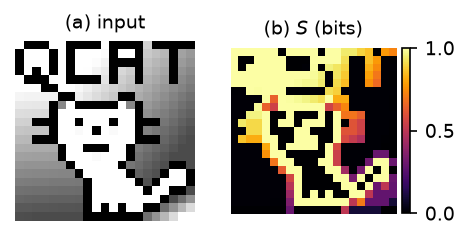

Published figure, `figures/paper/fig_entanglement_map.png`:

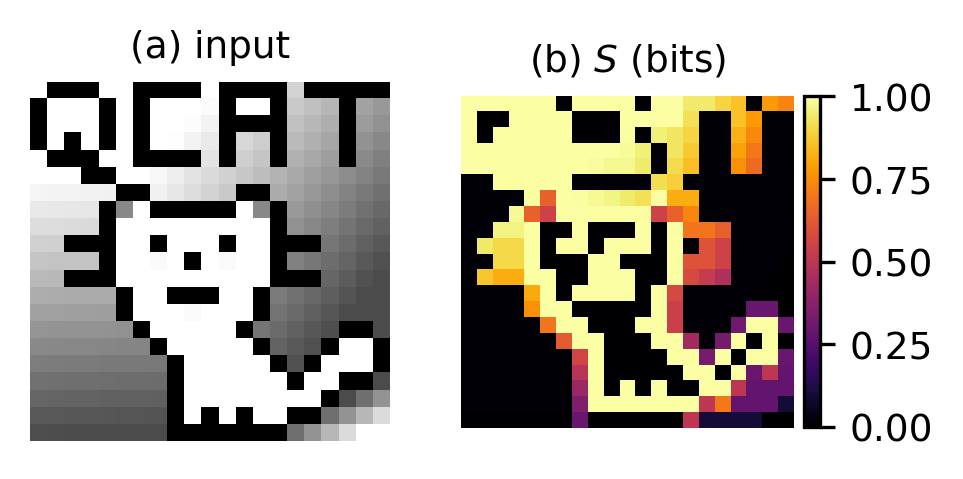

In [25]:
show(
    entanglement.fig_entanglement_map(save=FIGURES / "fig_entanglement_map.png"), dpi=150
)
reference("fig_entanglement_map.png", width=420)

Fig. 8: entropy across a cut, mean and standard deviation over 12 random payloads.

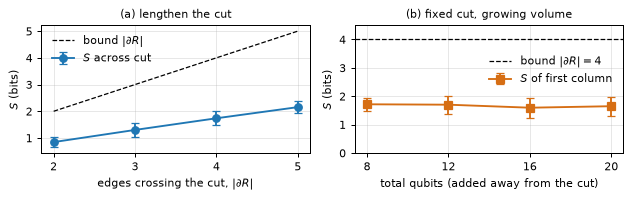

Published figure, `figures/paper/fig_area_law.png`:

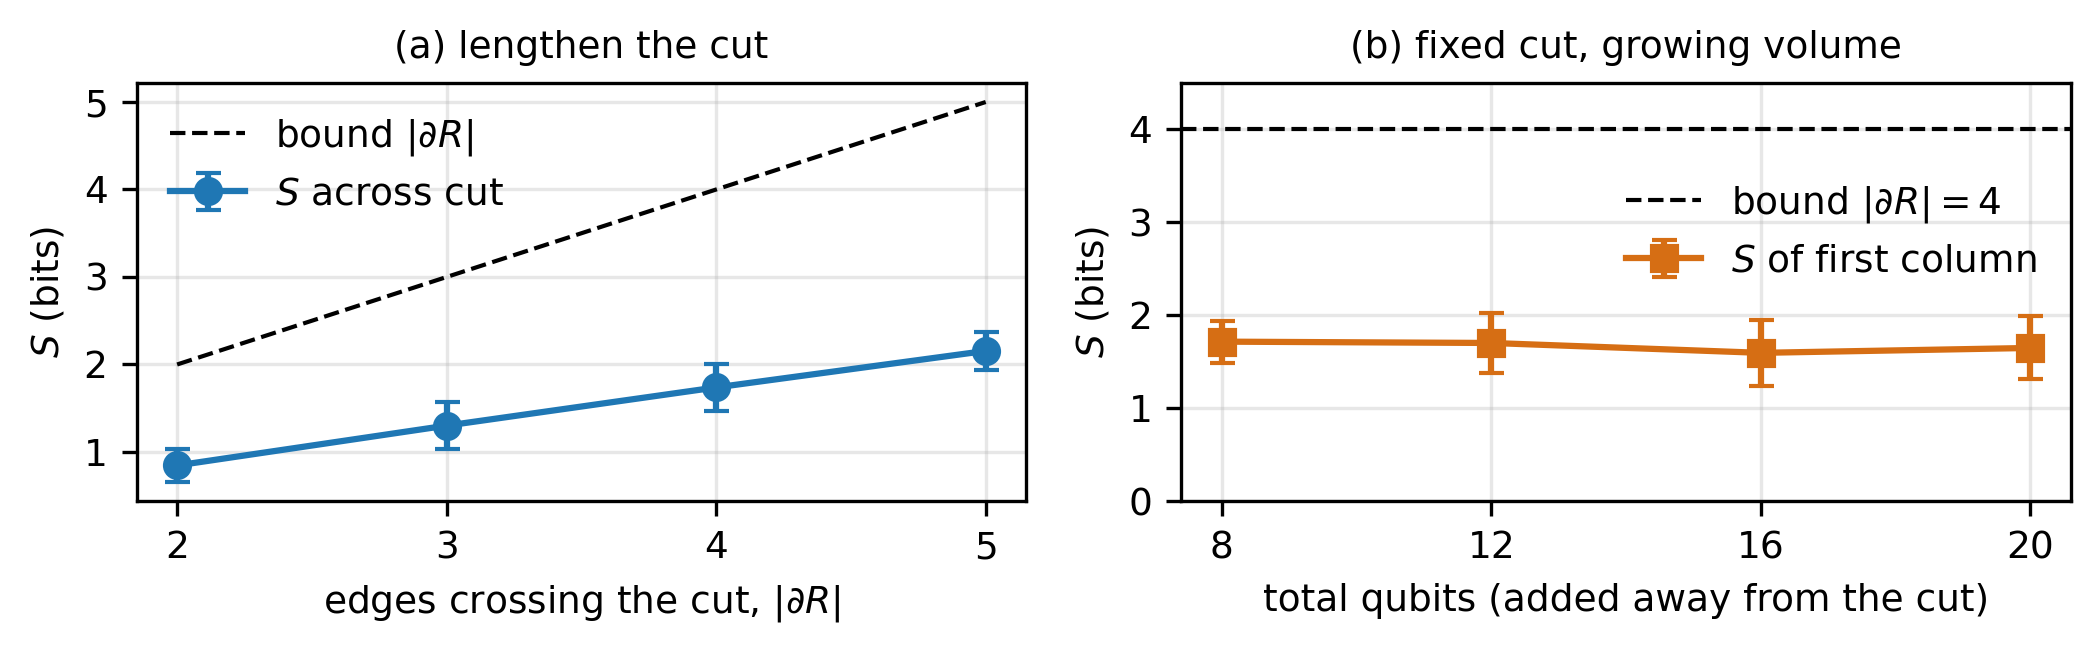

In [26]:
show(entanglement.fig_area_law(save=FIGURES / "fig_area_law.png"))
reference("fig_area_law.png", width=700)

Pixel comparison with the published PNGs. With matplotlib 3.10.9, the version that
made the published files, both are byte-identical; with other versions the text is
rendered slightly differently, which here also changes the image size by a few
pixels (REPRODUCIBILITY.md, section e).

In [27]:
pd.DataFrame(
    [
        pixel_comparison("fig_entanglement_map.png", "fig_entanglement_map.png"),
        pixel_comparison("fig_area_law.png", "fig_area_law.png"),
    ]
)

,regenerated,published,fraction of differing pixels
0,figures/fig_entanglement_map.png 963x482,figures/paper/fig_entanglement_map.png 963x479,not compared: sizes differ
1,figures/fig_area_law.png 2108x661,figures/paper/fig_area_law.png 2100x654,not compared: sizes differ


Table 3: negativity N and mutual information I (bits) of qubit pairs of a 3x4
lattice by pair type and graph distance, over 40 random payloads.

In [28]:
entanglement.table_pairs()

,,n_pairs,mean N,max N,mean I,max I
pair,distance,,,,,
DA,1,17,0.030943,0.333564,1.889113e-01,1.329151e+00
AA,2,11,0.000021,0.009133,5.191030e-02,3.955673e-01
DD,2,11,0.000000,0.000000,1.825074e-02,2.903485e-01
DA,3,17,0.000000,0.000000,2.408914e-03,7.025141e-02
AA,4,4,0.000000,0.000000,5.584161e-04,9.919823e-03
DD,4,4,0.000000,0.000000,1.688233e-15,3.996803e-15
DA,5,2,0.000000,0.000000,1.794398e-15,5.107026e-15


In [29]:
check("entanglement")

,item,paper,reproduced,match,kind,status
0,tab:pairs DA d=1 mean N,0.031,0.031,True,number,match
1,tab:pairs DA d=1 max N,0.334,0.334,True,number,match
2,tab:pairs DA d=1 mean I,0.189,0.189,True,number,match
3,tab:pairs DA d=1 max I,1.329,1.329,True,number,match
4,tab:pairs AA d=2 mean N,<1e-4,<1e-4,True,number,match
5,tab:pairs AA d=2 max N,0.009,0.009,True,number,match
6,tab:pairs AA d=2 mean I,0.052,0.052,True,number,match
7,tab:pairs AA d=2 max I,0.396,0.396,True,number,match
8,tab:pairs DD d=2 mean N,0,0,True,number,match
9,tab:pairs DD d=2 max N,0,0,True,number,match


## 7. App. D: what the coherences mean (Table 4, Fig. 9)

Fig. 9 shows experiment B of the coherence run on `ibm_phoenix` (job
`davnlrlj371s73dn89o0`, 2026-10-02, 8192 shots per circuit): each pair of adjacent
QCAT pixels is encoded as an isolated degree-one super-pixel on one of 60 disjoint
couplers, a Hadamard is applied to its address qubit, and K = 2 P(address = 0) - 1 is
compared with cos(pi (v_i - v_j) / 2). The maps show 1 - K. Data:
`results/hardware/coherence/tables/phoenix_B_pairs.csv`, re-derived below from the
raw counts.

Known difference in wording (REPRODUCIBILITY.md): the text and caption describe
K_a of the full-lattice encoded state (Eq. Ka); the figure shows the pair-by-pair
experiment B. All numbers printed in the figure match.

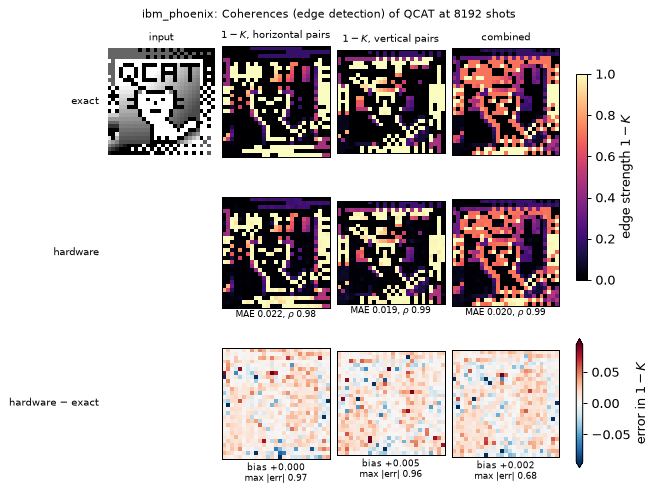

Published figure, `figures/paper/coherences.png`:

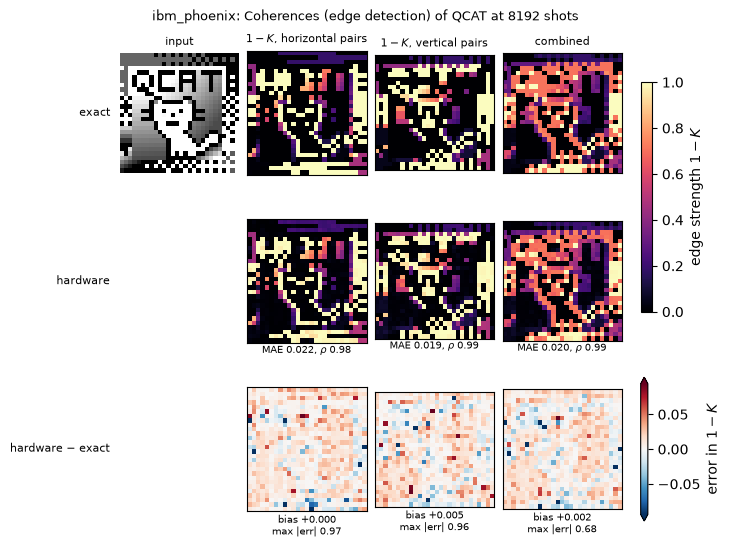

In [30]:
show(coherence.coherence_figure(save=FIGURES / "coherences.png"))
reference("coherences.png", width=600)

In [31]:
coherence.edge_metrics()

,n,MAE,RMSE,bias,max |err|,rho
horizontal,756.0,0.022387,0.089220,0.000305,0.971191,0.976546
vertical,756.0,0.018659,0.060373,0.004517,0.963623,0.989969
combined,729.0,0.019663,0.056106,0.002143,0.683606,0.988198


In [32]:
pairs = coherence.rederive_pairs_from_counts()
print(
    f"largest |K re-derived - K stored| over {len(pairs)} pairs: {pairs['|diff|'].max()}"
)

largest |K re-derived - K stored| over 1512 pairs: 0.0


Table 4: no code or data survive, and the paper does not state the payload encoded
on the 3x4 lattice, which sets K_a and the bias of the classical route. The
"undefined" column does not depend on the payload and is reproduced; the
interference column only fixes |K_a| through RMS = sqrt((1 - K_a^2) / N).

In [33]:
for item in coherence.KCOMPARE_UNSPECIFIED:
    print("not specified in the paper:", item)

not specified in the paper: the payload: which values were encoded on the 3x4 lattice (an image, a random draw and from which distribution, a fixed payload or a new one per repetition); K_a and the bias of the classical route depend on it
not specified in the paper: the value-to-angle map (presumably theta = pi * value, value range (0, 1))
not specified in the paper: how repetitions in which an address configuration received no shots enter the classical RMS error and bias (left out, or counted with some default angle)
not specified in the paper: which address configurations count for 'undefined' (those of the data qubits next to the address qubit, which K_a needs, or those of every data qubit)
not specified in the paper: the random seeds


In [34]:
coherence.kcompare_table()

,interference RMS (paper),classical RMS (paper),classical bias (paper),undefined (paper),"undefined (reproduced, 200 rep.)",undefined (20000 rep.)
shots,,,,,,
64,0.113,0.169,-0.158,0.26,0.225,0.23525
256,0.054,0.056,-0.044,0.00,0.000,0.00000
1024,0.029,0.022,-0.015,0.00,0.000,0.00000
4096,0.015,0.010,-0.006,0.00,0.000,0.00000
65536,0.004,0.003,-0.001,0.00,0.000,0.00000


In [35]:
coherence.kcompare_interference_rms()

,bound 1/sqrt(N),paper RMS,implied |K_a|
shots,,,
64,0.125000,0.113,0.427532
256,0.062500,0.054,0.503492
1024,0.031250,0.029,0.372580
4096,0.015625,0.015,0.280000
65536,0.003906,0.004,NaN


For illustration only, not a reproduction: the table re-implemented from the
paper's description, on a payload of 48 values drawn uniformly from [0, 1] (seed 1).
The payload is our choice, not the paper's.

In [36]:
coherence.kcompare_simulation(np.random.default_rng(1).random(48))

,exact K_a,interference RMS,classical RMS,classical bias,undefined
shots,,,,,
64,0.544253,0.115035,0.198860,-0.187660,0.28
256,0.544253,0.049189,0.072382,-0.059835,0.00
1024,0.544253,0.026780,0.025195,-0.017130,0.00
4096,0.544253,0.014298,0.011931,-0.004991,0.00
65536,0.544253,0.003241,0.002854,-0.000188,0.00


Known difference (REPRODUCIBILITY.md): the "undefined" fraction at N = 64 is 26% in
the paper and 22% here (200 repetitions, seed 0); with 20000 repetitions it is
23.5%, so the printed value is within one standard error (3.0 points) of a
200-repetition estimate.

In [37]:
check("coherence")

,item,paper,reproduced,match,kind,status
0,fig:coherences shots,8192,8192,True,number,match
1,fig:coherences horizontal MAE,0.022,0.022,True,number,match
2,fig:coherences horizontal rho,0.98,0.98,True,number,match
3,fig:coherences vertical MAE,0.019,0.019,True,number,match
4,fig:coherences vertical rho,0.99,0.99,True,number,match
5,fig:coherences combined MAE,0.020,0.020,True,number,match
6,fig:coherences combined rho,0.99,0.99,True,number,match
7,fig:coherences horizontal bias,+0.000,+0.000,True,number,match
8,fig:coherences horizontal max |err|,0.97,0.97,True,number,match
9,fig:coherences vertical bias,+0.005,+0.005,True,number,match


## 8. App. E: full single-qubit tomography and the clamp (Table 5, Fig. 11)

Table 5 follows from the mode definitions in `tessa.MODES`. Fig. 10 (the clamp
region on the Bloch sphere) is a schematic drawn in TikZ, published as
`figures/paper/fig_clamp_sphere.pdf`. Fig. 11 compares sampled reconstruction errors
of the pair encodings with the predictions of the appendix, for clamps from
0.05 pi to 0.45 pi (shot noise only, 4096 shots per basis, 4x4 lattice, three random
payloads); data: the `e2_clamp` block of
`results/simulation/pair_encoding/pair_encoding_results.json`.

In [38]:
pair_encoding.table_modes()

,values,phi,clamped,shots_per_value
bases,,,,
Z,C,---,---,1.0
"Z,X",2C,"[0,pi]",theta,1.0
"Z,X,Y",2C,"[0,2pi)","theta, phi*",1.5
"Z,X,Y (sign bit)",2C + C bits,"[0,pi] + sign","theta, phi",1.5


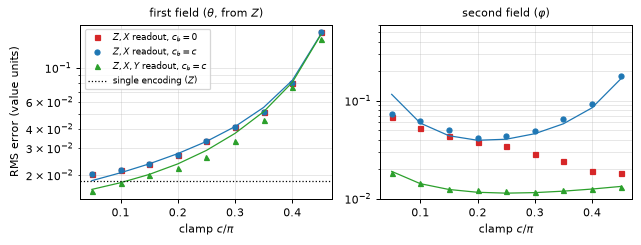

Published figure, `figures/paper/fig_pair_clamp.png`:

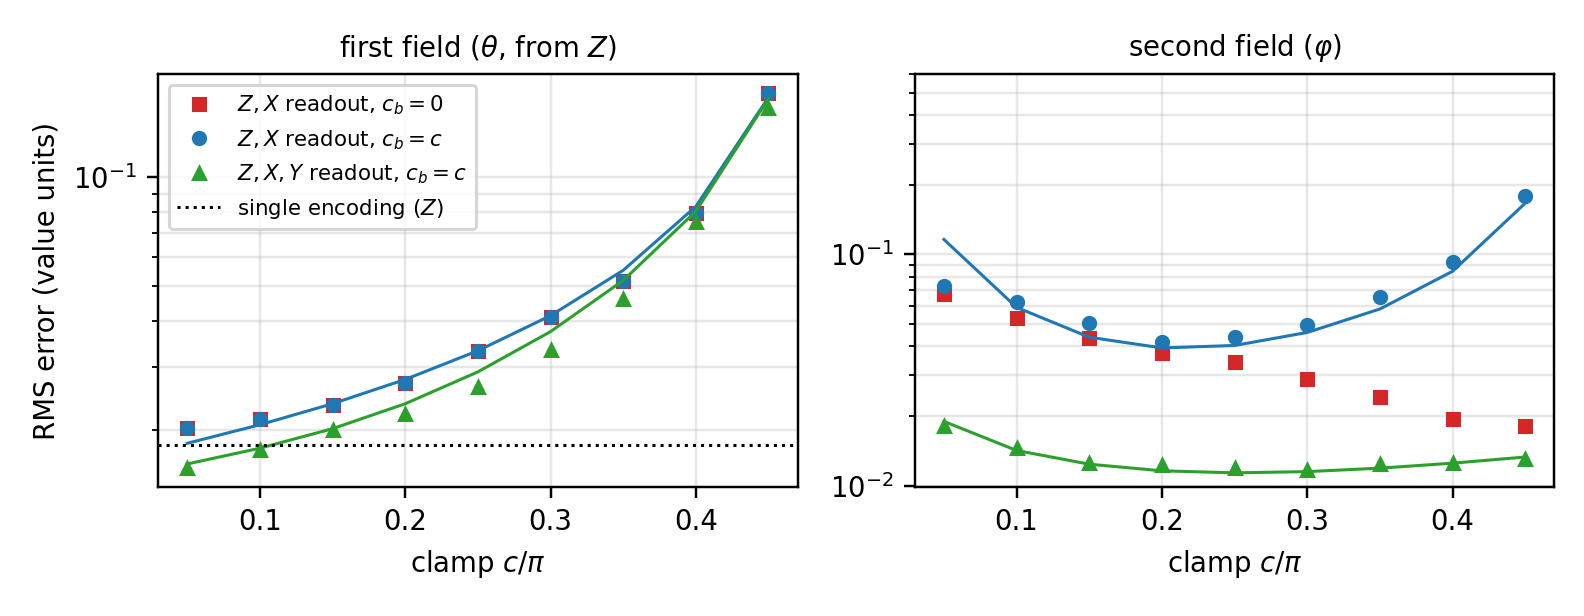

regenerated                           figures/fig_pair_clamp.png 1584x616
published                       figures/paper/fig_pair_clamp.png 1584x616
fraction of differing pixels                                       0.2106
dtype: str

In [39]:
show(pair_encoding.fig_pair_clamp(save=FIGURES / "fig_pair_clamp.png"))
reference("fig_pair_clamp.png", width=700)
pixel_comparison("fig_pair_clamp.png", "fig_pair_clamp.png")

The numbers behind the statements of the appendix (RMS errors in data units at the
default clamp c = 0.2 pi, and the half-circle / full-circle ratio quoted as "about
three times").

In [40]:
pd.Series(pair_encoding.claims())

single rms_a                           0.018254
pair_full rms_a @0.2pi                 0.022144
pair_full rms_b @0.2pi                 0.012234
pair_cbc rms_a @0.2pi                  0.026991
pair_cbc rms_b @0.2pi                  0.042022
pair_cb0 rms_b @0.2pi                  0.037547
ratio half(c_b=c)/full second field    3.434795
ratio half(c_b=0)/full second field    3.069063
best clamp half circle c_b=c                0.2
c_b=0 second field monotone in c           True
max |sampled/pred - 1|, all clamps       0.3728
max |sampled/pred - 1|, c >= 0.1pi     0.152795
dtype: object

In [41]:
check("pair_encoding")

,item,paper,reproduced,match,kind,status
0,fig:pairclamp shots per basis,4096,4096,True,number,match
1,fig:pairclamp lattice,4x4,4x4,True,label,match
2,ratio half(c_b=c)/full second field @0.2pi,about 3,3.43,True,claim,match
3,ratio half(c_b=0)/full second field @0.2pi,about 3,3.07,True,claim,match
4,full-circle second field < single encoding (rms),True,0.0122 < 0.0183,True,claim,match
5,full-circle first field improves slightly (rms),True,0.0221 < 0.0270,True,claim,match
6,"half circle, c_b=c: best clamp c/pi",about 0.2,0.20,True,claim,match
7,"half circle, c_b=0: keeps improving with c",True,True,True,claim,match
8,sampled vs Eq. sigmapair: agree except smallest clamp (max rel. dev.),agree,"0.15 (c>=0.1pi), 0.37 (all)",True,claim,match
9,tab:modes Z shots/value,1,1,True,number,match


Re-running the clamp sweep with the `tessa` API (about 10 s) and comparing every
number with the stored block:

In [42]:
rerun = pair_encoding.compare_rerun("e2_clamp", pair_encoding.rerun_e2())
print(
    f"{len(rerun)} numbers re-run, largest absolute difference: {rerun['abs_diff'].max()}"
)

147 numbers re-run, largest absolute difference: 2.7755575615628914e-17


## 9. App. F: dynamic-range recovery (Table 6)

Image columns: MAE of the Z images of the QCAT runs after each DRR method, computed
from the hardware images decoded from the raw counts (`qcat.image_metrics`; checked
against `stats.json` in section 4).

In [43]:
qcat.drr_image_table()

,scalars,Phoenix,Fez
method,,,
none,0,0.129887,0.131244
abs_max,1,0.120296,0.120898
min_max,2,0.114373,0.085774
percentile,2,0.085017,0.076185
mean_std,2,0.074741,0.077570
min_avg_max,3,0.112195,0.089671


In [44]:
check("qcat", "tab:drr")

,item,paper,reproduced,match,kind,status
0,tab:drr none Phoenix,0.130,0.130,True,number,match
1,tab:drr none Fez,0.131,0.131,True,number,match
2,tab:drr abs_max Phoenix,0.120,0.120,True,number,match
3,tab:drr abs_max Fez,0.121,0.121,True,number,match
4,tab:drr min_max Phoenix,0.114,0.114,True,number,match
5,tab:drr min_max Fez,0.086,0.086,True,number,match
6,tab:drr percentile Phoenix,0.085,0.085,True,number,match
7,tab:drr percentile Fez,0.076,0.076,True,number,match
8,tab:drr mean_std Phoenix,0.075,0.075,True,number,match
9,tab:drr mean_std Fez,0.078,0.078,True,number,match


Pitch columns: exact-note fraction and pitch MAE (semitones) of the MIDI round trip
after each DRR method.

Known difference (REPRODUCIBILITY.md): the paper labels these columns, and Table 7,
as ibm_fez hardware results. No hardware data for them survive, and every printed
number is reproduced by the FakeFez noise-model simulation that the original
notebook ran (machine-average noise of the FakeFez calibration, each super-pixel
simulated alone, 8000 shots, seed 1, input `data/midi/telemann_small.mid`). The
values below are that simulation, cached in `results/simulation/midi_audio/` (about
15 s to recompute). `abs_max` is printed as "---" in the paper.

In [45]:
audio_midi.table_drr_pitch()

,exact (%),MAE (st)
none,18.731988,2.126801
abs_max,0.288184,7.564841
min_max,8.357349,1.832853
percentile,12.391931,1.665706
mean_std,49.279539,0.657061
min_avg_max,23.342939,1.132565


In [46]:
check("audio_midi", "tab:drr")

,item,paper,reproduced,match,kind,status
0,tab:drr pitch none exact (%),18.7,18.7,True,number,match
1,tab:drr pitch none MAE (st),2.13,2.13,True,number,match
2,tab:drr pitch abs_max exact (%),---,0.3,False,not printed,known difference
3,tab:drr pitch abs_max MAE (st),---,7.56,False,not printed,known difference
4,tab:drr pitch min_max exact (%),8.4,8.4,True,number,match
5,tab:drr pitch min_max MAE (st),1.83,1.83,True,number,match
6,tab:drr pitch percentile exact (%),12.4,12.4,True,number,match
7,tab:drr pitch percentile MAE (st),1.67,1.67,True,number,match
8,tab:drr pitch mean_std exact (%),49.3,49.3,True,number,match
9,tab:drr pitch mean_std MAE (st),0.66,0.66,True,number,match


## 10. App. G: wavetable synthesis (Fig. 12)

Fig. 12 showed a wavetable reconstructed on ibm_fez; the counts, job id and
reconstructed table of that run were not saved. The figure below is a re-creation
from a simulation of the same procedure (448-sample sine, FakeFez machine-average
noise, 8000 shots, seed 1, `min_max` DRR as the caption states, while the original
notebook divided the table by its maximum) and is saved as
`figures/sound_example_recreation.png`, next to the published
`figures/paper/sound_example.png`. The caption also gives 4096 shots, while the
original notebook used 8192 (REPRODUCIBILITY.md).

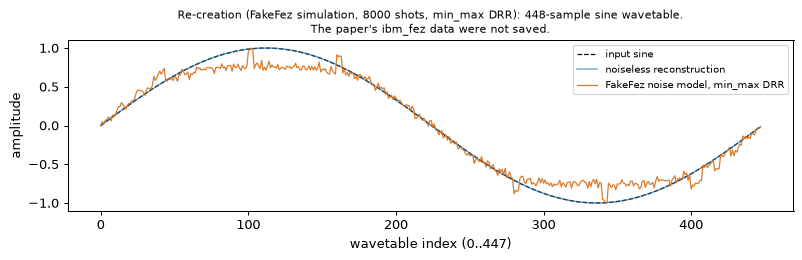

Published figure, `figures/paper/sound_example.png`:

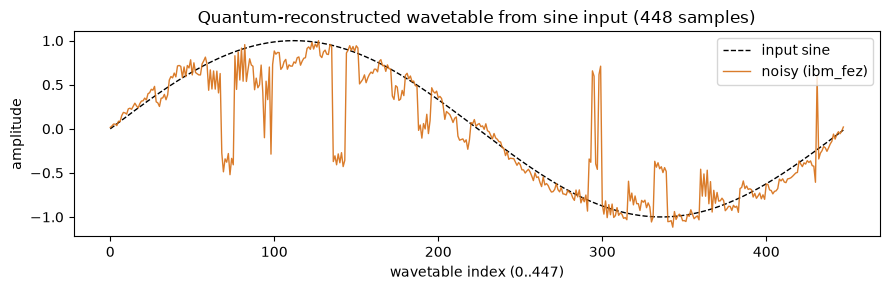

In [47]:
show(audio_midi.fig_sound(save=FIGURES / "sound_example_recreation.png"))
reference("sound_example.png", width=700)

In [48]:
check("audio_midi", "fig:sound")

,item,paper,reproduced,match,kind,status
0,fig:sound re-creation: FakeFez mean |err| (original notebook print...,not in paper,0.289,True,not printed,match


## 11. App. G: symbolic music (Table 7)

Exact-note fraction, pitch MAE and duration MAE of the MIDI round trip for the
duration warps. As for the pitch columns of Table 6, the rows the paper labels
"hardware" are the FakeFez noise-model simulation (REPRODUCIBILITY.md).

In [49]:
audio_midi.table_midi()

,exact (%),pitch (st),dur. (s)
noiseless simulation,100.000000,0.000000,1.280756e-15
"FakeFez sim, raw (paper: hardware, raw)",18.731988,2.126801,4.908655e-01
"FakeFez sim, linear (paper: hardware, linear)",49.279539,0.657061,2.083498e-01
"FakeFez sim, log (paper: hardware, log)",49.279539,0.657061,1.447129e-01
"FakeFez sim, square root (paper: hardware, square root)",49.279539,0.657061,1.167507e-01


In [50]:
check("audio_midi", "tab:midi")

,item,paper,reproduced,match,kind,status
0,tab:midi noiseless simulation exact (%),100.0,100.0,True,number,match
1,tab:midi noiseless simulation pitch (st),0.00,0.00,True,number,match
2,tab:midi noiseless simulation dur. (s),0.000,0.000,True,number,match
3,"tab:midi hardware, raw exact (%)",18.7,18.7,True,number,match
4,"tab:midi hardware, raw pitch (st)",2.13,2.13,True,number,match
5,"tab:midi hardware, raw dur. (s)",0.491,0.491,True,number,match
6,"tab:midi hardware, linear exact (%)",49.3,49.3,True,number,match
7,"tab:midi hardware, linear pitch (st)",0.66,0.66,True,number,match
8,"tab:midi hardware, linear dur. (s)",0.208,0.208,True,number,match
9,"tab:midi hardware, log exact (%)",49.3,49.3,True,number,match


In [51]:
for item, why in audio_midi.KNOWN_DISCREPANCIES.items():
    print(f"- {item}: {why}\n")

- tab:midi / tab:drr pitch: source: The rows are labelled hardware ('hardware, raw', 'Fez score') but every number is the FakeFez noise-model simulation reproduced here; the one real ibm_fez MIDI run (2026-07-29, 8192 shots, min_max: 39.5 % exact, 1.62 st, 0.469 s) saved no counts and is not in the paper.

- tab:drr pitch abs_max exact (%): Printed as '---' (the original notebook did not run abs_max); the same simulation gives 0.3 %, since MIDI note numbers 62-88 are not anchored at zero.

- tab:drr pitch abs_max MAE (st): Printed as '---'; the same simulation gives 7.56 semitones.

- fig:sound: data: The ibm_fez wavetable of the paper saved no counts, job id or table, so the figure here is a FakeFez-simulation re-creation.

- fig:sound: caption: The caption says 4096 shots and min_max DRR, but the notebook that made the figure used 8192 shots and divided by the maximum (wt / |max(wt)|).



## 12. App. G: DNA and protein sequences (Fig. 13, Fig. 14, Table 8)

Seven sequences from `data/sequences/genetic_sequences.txt` were stored on
`ibm_phoenix` in two jobs (`db91e1694fic73eua10g`, `db980g0c77vs73811r9g`, 2026-10-16,
32768 shots per circuit) with the constellation and the angle encoding. The hardware
columns are decoded here from the raw shots in `results/hardware/genetic/*.npz`
(about 12 s), using the graph and slot order stored in each job's ticket and the
constellation point sets stored with the runs
(`results/hardware/genetic/constellation_points.npz`; `tessa.constellation` computes
them with a rounding-sensitive iteration, so the decode does not recompute them). The
simulated columns come from `results/simulation/genetic/metrics.json`. The "best"
columns are the best of five DRR methods, chosen with knowledge of the true
sequence (as the caption of Table 8 says): an upper bound, not a blind
post-processing result.

In [52]:
hw = genetic.hardware_results()
table = genetic.table_genetic(hw=hw)
table.round(1)

,,per_slot,sim_noiseless_raw,sim_noise_raw,sim_noise_min_max,sim_noise_best,sim_noise_best_method,hw_raw,hw_min_max,hw_best,hw_best_method
sequence,encoding,,,,,,,,,,
POLG2 mRNA,constellation,2,100.0,88.8,88.3,89.0,mean_std,83.8,84.3,84.3,min_max
SUR1 isoform 2,constellation,2,100.0,63.7,63.0,69.5,mean_std,21.0,21.5,22.6,percentile
MT-CO3,constellation,1,100.0,91.1,91.5,91.5,min_max,92.1,91.5,92.3,min_avg_max
RRM1,constellation,1,100.0,86.0,86.1,86.2,percentile,69.9,69.3,69.9,mean_std
pikachurin,constellation,2,100.0,92.1,90.4,94.5,mean_std,24.0,22.2,25.8,mean_std
Sonic hedgehog,constellation,1,100.0,100.0,100.0,100.0,min_max,73.4,73.2,76.2,min_avg_max
p53,constellation,1,100.0,100.0,100.0,100.0,min_max,70.5,70.0,71.5,mean_std
POLG2 mRNA,angle,2,100.0,68.3,72.8,83.4,mean_std,57.0,47.5,68.5,mean_std
SUR1 isoform 2,angle,2,94.5,16.4,26.9,31.1,percentile,11.3,11.4,17.4,mean_std


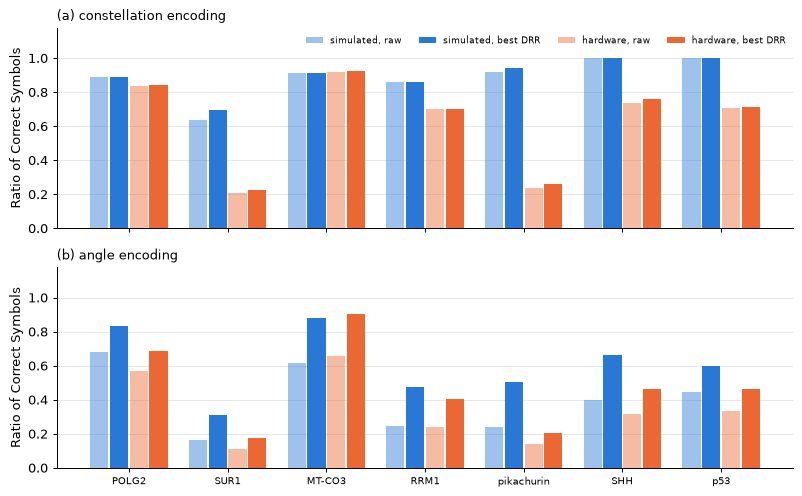

In [53]:
show(genetic.fig_genetic_results(save=FIGURES / "genetic_results.pdf", table=table))

The paper `\input`s the table rows and the macros (shots, backend, job ids) from
`results_table.tex` and `results_macros.tex`; the regenerated files are compared
with the paper's copies in `figures/paper/`.

In [54]:
tex_dir = genetic.PAPER_TEX
print(
    "results_table.tex identical:",
    genetic.table_genetic_tex(table) == (tex_dir / "results_table.tex").read_text(),
)
print(
    "results_macros.tex identical:",
    genetic.macros_tex(hw) == (tex_dir / "results_macros.tex").read_text(),
)

results_table.tex identical: True
results_macros.tex identical: True


Fig. 13 is TikZ; it is regenerated as text and compared with the published file.

In [55]:
tikz = genetic.constellation_tex(save=FIGURES / "constellation.tex")
print(
    "identical to figures/paper/constellation.tex:",
    tikz == (PAPER / "constellation.tex").read_text(),
)

identical to figures/paper/constellation.tex: True


Noiseless shot sweep (largest number of wrong symbols over five seeds), behind the
statement that 32768 is the smallest power of two with no error.

In [56]:
genetic.shot_sweep()

,POLG2_mRNA,SUR1_ABCC8_iso2,P53_HUMAN,PIKACHURIN_HUMAN,SHH_HUMAN
256,132,1256,55,833,66
512,12,1099,12,715,10
1024,0,854,1,563,2
2048,0,555,0,392,0
4096,0,248,0,185,0
8192,0,65,0,59,0
16384,0,3,0,5,0
32768,0,0,0,0,0
65536,0,0,0,0,0


Known difference (REPRODUCIBILITY.md): the text gives a minimum spacing of 0.156 rad
for the 400-point constellation; the stored point set, with which every hardware cell
above is reproduced, has 0.163 rad. The point set comes from a repulsion iteration
whose minimum spacing is sensitive to rounding, so the printed value may come from
another platform or an earlier version of the code.

In [57]:
check("genetic", table=genetic.check_against_paper(hw=hw)).query("status != 'match'")

,item,paper,reproduced,match,kind,status
121,"constellation 400 points, min spacing (rad)",0.156,0.163,False,number,known difference


In [58]:
summary("genetic")

number: 115 compared with the paper: 114 match, 1 known difference.
label: 10 compared with the paper: 10 match.


## 13. Summary

All comparisons with the paper, per module (`tessa_paper.checks`), counted by kind:
printed numbers (and how many match or differ), labels and macros, qualitative
claims, and values not printed in the paper. "differ" rows are the known differences
explained in the sections above and in REPRODUCIBILITY.md; "UNEXPECTED" would be a
mismatch that is not documented.

In [59]:
all_rows = pd.concat(CHECKS.values(), ignore_index=True)
assert set(all_rows["module"]) == set(checks.ITEMS)
overview = checks.overview(all_rows)
total = overview.iloc[-1]
print(
    f"{total['numbers']} numbers printed in the paper compared: {total['match']} match, "
    f"{total['differ']} differ (documented). Also compared: {total['labels']} labels "
    f"and macros ({total['labels match']} match), {total['claims']} qualitative "
    f"claims ({total['claims hold']} hold), {total['not printed']} values not printed "
    "in the paper."
)
overview

319 numbers printed in the paper compared: 313 match, 6 differ (documented). Also compared: 21 labels and macros (21 match), 10 qualitative claims (10 hold), 3 values not printed in the paper.


,module,paper items,numbers,match,differ,labels,labels match,claims,claims hold,not printed,UNEXPECTED
0,qcat,"Fig. 4, Table 1, Table 6 (images), abstract",65,64,1,0,0,0,0,0,0
1,pixel_art,"Fig. 1, Fig. 6",52,51,1,10,10,0,0,0,0
2,lattices,"Fig. 5, Table 2 (qubits)",3,3,0,0,0,0,0,0,0
3,circuits,Table 2,8,6,2,0,0,0,0,0,0
4,entanglement,"Fig. 7, Fig. 8, Table 3",28,28,0,0,0,3,3,0,0
5,coherence,"Fig. 9, Table 4",18,17,1,0,0,0,0,0,0
6,pair_encoding,"Fig. 11, Table 5",5,5,0,1,1,7,7,0,0
7,audio_midi,"Fig. 12, Table 6 (pitch), Table 7",25,25,0,0,0,0,0,3,0
8,genetic,"Fig. 13, Fig. 14, Table 8",115,114,1,10,10,0,0,0,0
9,total,,319,313,6,21,21,10,10,3,0


In [60]:
checks.differences(all_rows)

,module,item,kind,paper,reproduced,status
0,pixel_art,fig:pixelart Apple -> moth (palette) shots,number,8192,16384,known difference
1,qcat,abstract largest number of values encoded and decoded,number,1584,1568,known difference
2,circuits,tab:prior Tessa Z 2Q depth,number,19,23,known difference
3,circuits,"tab:prior Tessa Z,X 2Q depth",number,39,43,known difference
4,coherence,tab:kcompare N=64 undefined,number,26%,22%,known difference
5,audio_midi,tab:drr pitch abs_max exact (%),not printed,---,0.3,known difference
6,audio_midi,tab:drr pitch abs_max MAE (st),not printed,---,7.56,known difference
7,genetic,"constellation 400 points, min spacing (rad)",number,0.156,0.163,known difference


In [61]:
assert total["UNEXPECTED"] == 0
packages = [
    "tessa-paper",
    "qiskit",
    "qiskit-aer",
    "qiskit-ibm-runtime",
    "numpy",
    "scipy",
    "matplotlib",
    "pandas",
]
print(f"Python {platform.python_version()} on {platform.system()} {platform.machine()}")
for name in packages:
    print(f"{name:20s} {version(name)}")
print(f"Run time of this notebook: {time.perf_counter() - START:.0f} s")

Python 3.12.3 on Linux x86_64
tessa-paper          1.0.0
qiskit               2.6.2
qiskit-aer           0.18.2
qiskit-ibm-runtime   0.52.1
numpy                2.5.4
scipy                1.18.1
matplotlib           3.11.2
pandas               3.1.1
Run time of this notebook: 47 s
